## 1 Introduction

E-Commerce Sales Analysis: Sales Trends, Customer Behavior, and Product Performance. All results come from the official historical workbook.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
print(ROOT)

/Users/siddhu/Documents/New project/ecommerce-sales-analysis


## 2 Business problem

Measure sales trends, customer purchasing and product contribution to guide investigations. Revenue does not imply profit.

In [2]:
questions=["Revenue and timing", "Product and geographic contribution", "Repeat purchasing and segments", "Cancellations and data quality"]
questions

['Revenue and timing',
 'Product and geographic contribution',
 'Repeat purchasing and segments',
 'Cancellations and data quality']

## 3 Dataset description

UCI Online Retail, credited to Daqing Chen (2015), CC BY 4.0, DOI 10.24432/C5BW33. Currency GBP.

In [3]:
from src.config import DATA_PATH, REQUIRED_COLUMNS
print(DATA_PATH)
print(REQUIRED_COLUMNS)

/Users/siddhu/Documents/New project/ecommerce-sales-analysis/data/Online Retail.xlsx
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## 4 Imports

Use the same calculation and chart functions as the command line and dashboard.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data_loader import load_data
from src.data_cleaning import inspect_data, clean_data
from src import analysis as a, theme, visualizations as v
from run_analysis import chart_specs, findings
theme.apply_matplotlib_theme()

## 5 Loading

The cache uses the source workbook fingerprint; raw data is never changed.

In [5]:
raw=load_data()
raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 6 Initial inspection

Inspect source dimensions, types and date range before any exclusions.

In [6]:
inspection=inspect_data(raw)
inspection

{'rows': 541909,
 'columns': 8,
 'dtypes': {'InvoiceNo': 'string',
  'StockCode': 'string',
  'Description': 'str',
  'Quantity': 'int64',
  'InvoiceDate': 'str',
  'UnitPrice': 'float64',
  'CustomerID': 'string',
  'Country': 'str'},
 'missing': {'InvoiceNo': 0,
  'StockCode': 0,
  'Description': 1454,
  'Quantity': 0,
  'InvoiceDate': 0,
  'UnitPrice': 0,
  'CustomerID': 135080,
  'Country': 0},
 'duplicates': 5268,
 'unique_invoices': 25900,
 'unique_customers': 4372,
 'unique_products': 4070,
 'date_min': '2010-12-01 08:26:00',
 'date_max': '2011-12-09 12:50:00',
 'negative_quantities': 10624,
 'zero_quantities': 0,
 'zero_prices': 2515,
 'negative_prices': 2,
 'unit_price_distribution': {'count': 541909.0,
  'mean': 4.611113626088514,
  'std': 96.75985306117937,
  'min': -11062.06,
  '25%': 1.25,
  '50%': 2.08,
  '75%': 4.13,
  'max': 38970.0}}

## 7 Data-quality assessment

Missing customer IDs are retained for sales. Exact duplicates are removed under an explicit assumption.

In [7]:
display(pd.Series(inspection["missing"]).to_frame("Missing rows"))
print("Exact duplicates:",inspection["duplicates"])

,Missing rows
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Exact duplicates: 5268


## 8 Cleaning

Quality and cancellation rows are kept separately; exclusion reasons reconcile.

In [8]:
sales,quality,report=clean_data(raw)
assert report["original_rows"]-report["duplicates_removed"]-report["excluded_rows"]==len(sales)
report

{'inspection': {'rows': 541909,
  'columns': 8,
  'dtypes': {'InvoiceNo': 'string',
   'StockCode': 'string',
   'Description': 'str',
   'Quantity': 'int64',
   'InvoiceDate': 'str',
   'UnitPrice': 'float64',
   'CustomerID': 'string',
   'Country': 'str'},
  'missing': {'InvoiceNo': 0,
   'StockCode': 0,
   'Description': 1454,
   'Quantity': 0,
   'InvoiceDate': 0,
   'UnitPrice': 0,
   'CustomerID': 135080,
   'Country': 0},
  'duplicates': 5268,
  'unique_invoices': 25900,
  'unique_customers': 4372,
  'unique_products': 4070,
  'date_min': '2010-12-01 08:26:00',
  'date_max': '2011-12-09 12:50:00',
  'negative_quantities': 10624,
  'zero_quantities': 0,
  'zero_prices': 2515,
  'negative_prices': 2,
  'unit_price_distribution': {'count': 541909.0,
   'mean': 4.611113626088514,
   'std': 96.75985306117937,
   'min': -11062.06,
   '25%': 1.25,
   '50%': 2.08,
   '75%': 4.13,
   'max': 38970.0}},
 'original_rows': 541909,
 'duplicates_removed': 5268,
 'excluded_by_reason': {'cancel

## 9 Feature engineering

Shared cleaning creates revenue, calendar fields, and merchandise/cancellation flags.

In [9]:
sales[["Revenue","Year","Month","YearMonth","DayOfWeek","Hour","InvoiceDateOnly","IsProduct"]].head()

,Revenue,Year,Month,YearMonth,DayOfWeek,Hour,InvoiceDateOnly,IsProduct
0,15.30,2010,12,2010-12,Wednesday,8,2010-12-01,True
1,20.34,2010,12,2010-12,Wednesday,8,2010-12-01,True
2,22.00,2010,12,2010-12,Wednesday,8,2010-12-01,True
3,20.34,2010,12,2010-12,Wednesday,8,2010-12-01,True
4,20.34,2010,12,2010-12,Wednesday,8,2010-12-01,True


## 10 KPIs

Gross positive sales include eligible non-product lines. Customer averages use identified revenue only.

In [10]:
k=a.kpis(sales)
display(pd.Series(k).to_frame("Value"))

,Value
revenue,1.064211e+07
units,5.572420e+06
invoices,1.996000e+04
identified_customers,4.338000e+03
products,3.907000e+03
mean_invoice_revenue,5.331719e+02
median_invoice_revenue,3.033000e+02
mean_customer_revenue,2.048688e+03
median_customer_revenue,6.685700e+02
repeat_customer_pct,6.558322e+01


## 11 EDA

Logarithmic histograms expose heavily skewed positive values without silently removing outliers.

,Quantity,UnitPrice,Revenue
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
std,156.280031,36.093028,271.693566
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


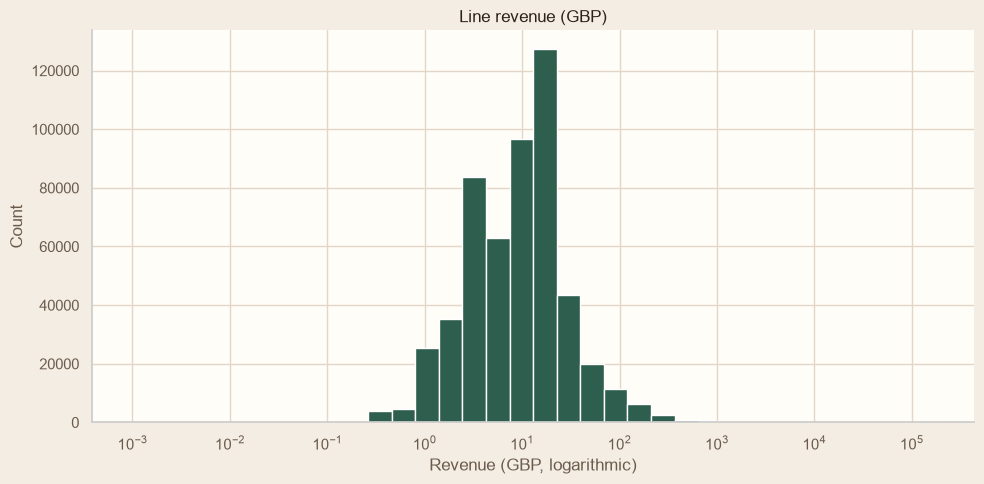

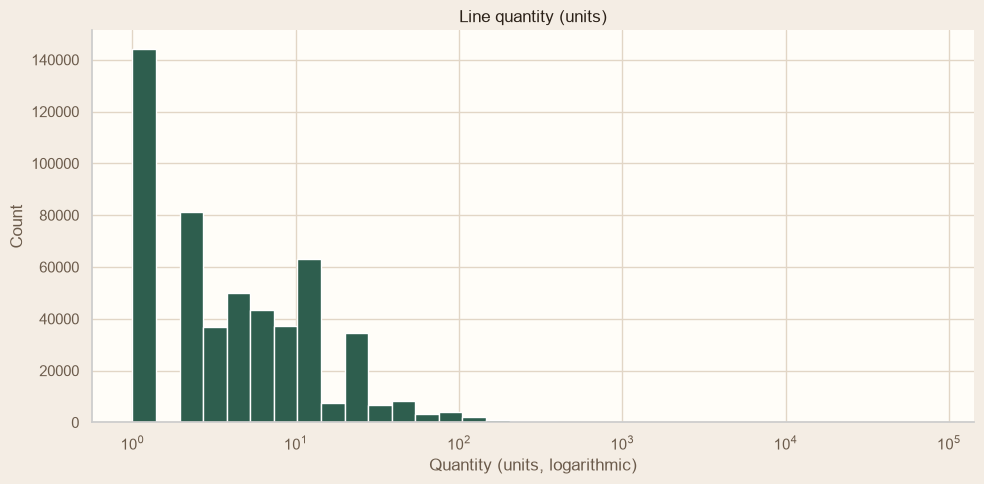

In [11]:
display(sales[["Quantity","UnitPrice","Revenue"]].describe())
for values,title in [(sales.Revenue,"Line revenue (GBP)"),(sales.Quantity,"Line quantity (units)")]:
    display(v.distribution(values,title,"Quantity (units, logarithmic)" if title.startswith("Line quantity") else "Revenue (GBP, logarithmic)")); plt.close("all")

## 12 Time series

Hatched boundary months are partial. Missing dates are not treated as evidence of zero demand. MoM involving a partial month is flagged.

,Revenue,Invoices,Partial,MoMPct,MoMPartial
Month,,,,,
2010-12,821452.730,1559,False,NaN,False
2011-01,689811.610,1086,False,-16.025404,False
2011-02,522545.560,1100,False,-24.248077,False
2011-03,716215.260,1454,False,37.062740,False
2011-04,536968.491,1246,False,-25.026941,False
2011-05,769296.610,1681,False,43.266620,False
2011-06,760547.010,1533,False,-1.137351,False
2011-07,718076.121,1475,False,-5.584256,False
2011-08,757841.380,1361,False,5.537750,False


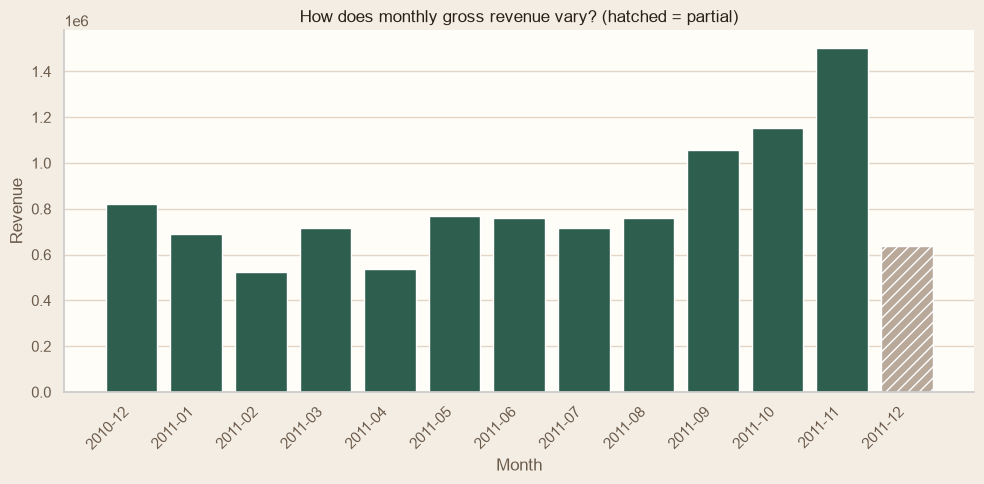

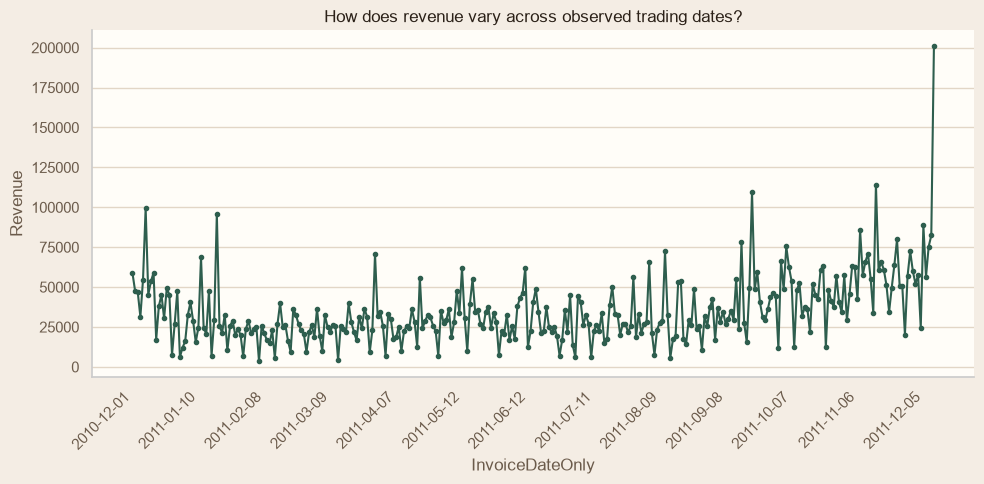

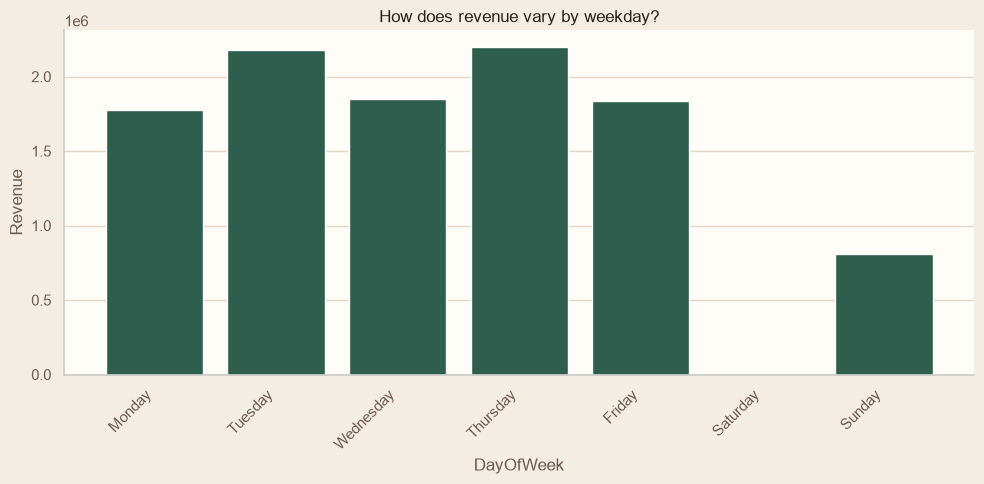

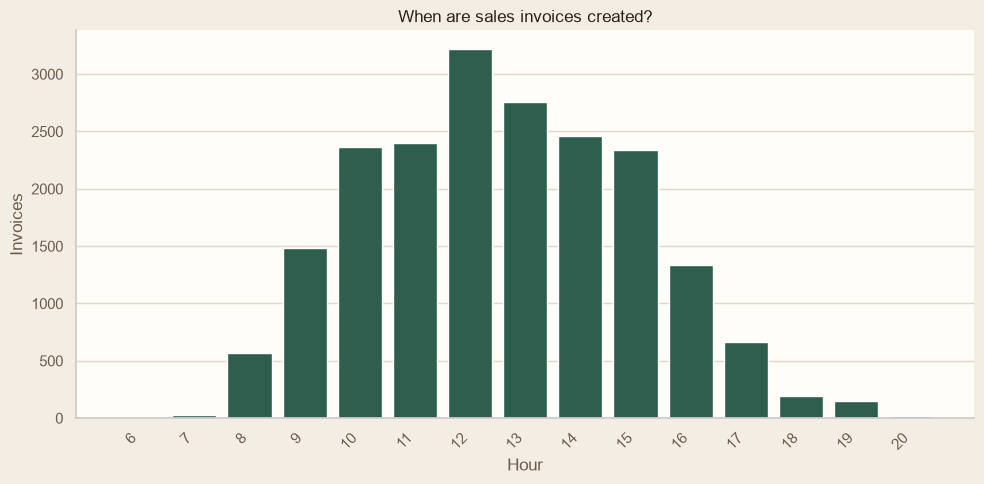

In [12]:
display(a.monthly(sales))
profiles=a.time_profiles(sales)
for name,table,value,title,kind,horizontal,cancel in chart_specs(sales,quality,report):
    if name in ["monthly","daily","weekday","hour"]:
        display(v.chart(table,value,title,kind,horizontal,cancel)); plt.close("all")

## 13 Products

Rank StockCode rather than inconsistent descriptions. Product shares retain all gross sales in the denominator.

,Description,Revenue,Quantity,RevenueSharePct,RevenueRank,QuantityRank
StockCode,,,,,,
22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1.636485,1.0,39.0
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1.583047,2.0,1.0
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641,0.981598,3.0,6.0
47566,PARTY BUNTING,99445.23,18283,0.934450,4.0,22.0
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,0.884785,5.0,5.0
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,0.767713,6.0,2.0
23084,RABBIT NIGHT LIGHT,66870.03,30739,0.628353,7.0,9.0
22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,0.609612,8.0,20.0
84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,0.553721,9.0,8.0


,Description,Revenue,Quantity,RevenueSharePct,RevenueRank,QuantityRank
StockCode,,,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1.583047,2.0,1.0
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,0.767713,6.0,2.0
22197,POPCORN HOLDER,51334.47,56898,0.482371,12.0,3.0
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951,0.129805,147.0,4.0
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,0.884785,5.0,5.0
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641,0.981598,3.0,6.0
21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396,0.199645,85.0,7.0
84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,0.553721,9.0,8.0
23084,RABBIT NIGHT LIGHT,66870.03,30739,0.628353,7.0,9.0


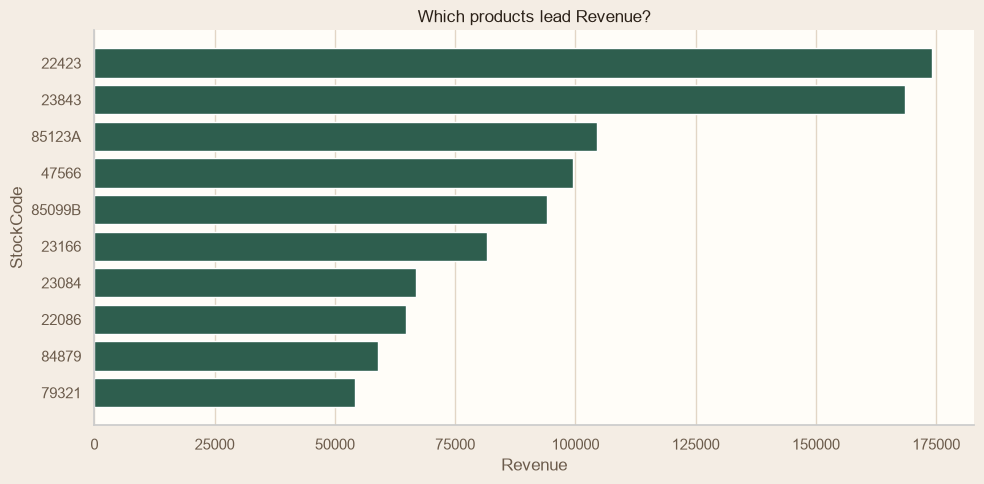

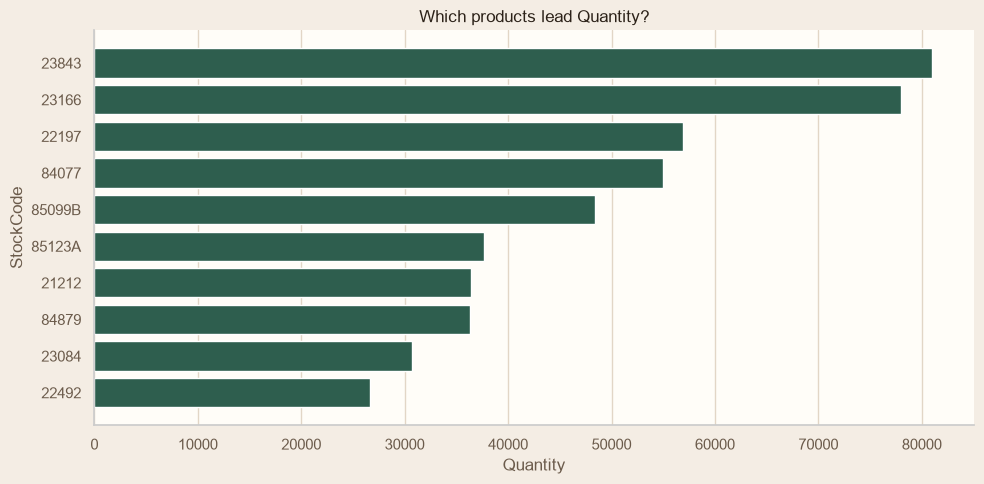

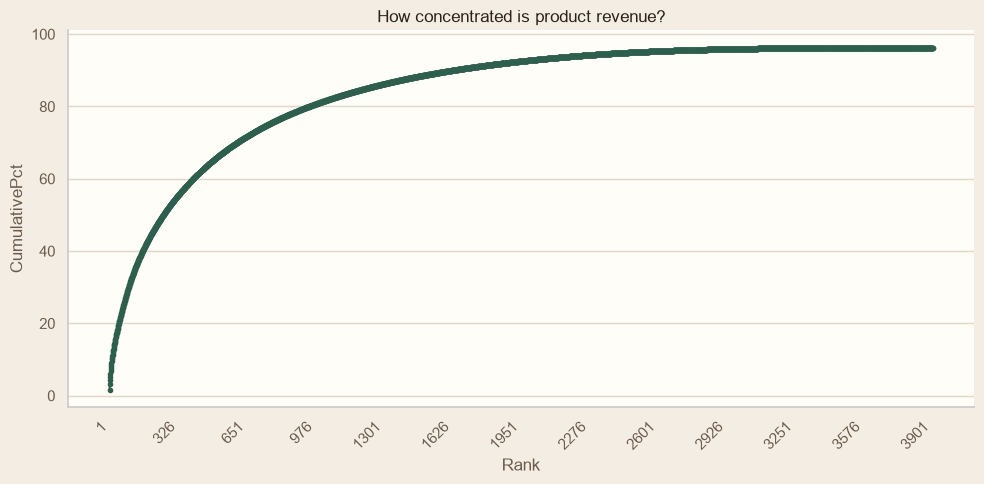

{'top5_products_pct': 6.020365149357262,
 'top10_products_pct': 9.088088517519251,
 'top10_customers_pct': 17.30193616848723,
 'top20pct_customers_pct': 74.68374942194758}

In [13]:
display(a.products(sales).head(10))
display(a.products(sales,"Quantity").head(10))
for by in ["Revenue","Quantity"]:
    display(v.chart(a.products(sales,by).head(10),by,"Which products lead "+by+"?",horizontal=True)); plt.close("all")
display(v.chart(a.pareto(sales).set_index("Rank"),"CumulativePct","How concentrated is product revenue?",kind="line")); plt.close("all")
a.concentration(sales)

## 14 Customers

Distinct invoices define frequency. Customer charts exclude unidentified rows and refer only to this observation period.

,Revenue,Frequency,LastPurchase
CustomerID,,,
14646,280206.02,73,2011-12-08 12:12:00
18102,259657.30,60,2011-12-09 11:50:00
17450,194390.79,46,2011-12-01 13:29:00
16446,168472.50,2,2011-12-09 09:15:00
14911,143711.17,201,2011-12-08 15:54:00
12415,124914.53,21,2011-11-15 14:22:00
14156,117210.08,55,2011-11-30 10:54:00
17511,91062.38,31,2011-12-07 10:12:00
16029,80850.84,63,2011-11-01 10:27:00


,Revenue,Frequency,LastPurchase
CustomerID,,,
12748,33053.19,209,2011-12-09 12:20:00
14911,143711.17,201,2011-12-08 15:54:00
17841,40519.84,124,2011-12-08 12:07:00
13089,58762.08,97,2011-12-07 09:02:00
14606,12076.15,93,2011-12-08 19:28:00
15311,60632.75,91,2011-12-09 12:00:00
12971,11189.91,86,2011-12-06 12:20:00
14646,280206.02,73,2011-12-08 12:12:00
16029,80850.84,63,2011-11-01 10:27:00


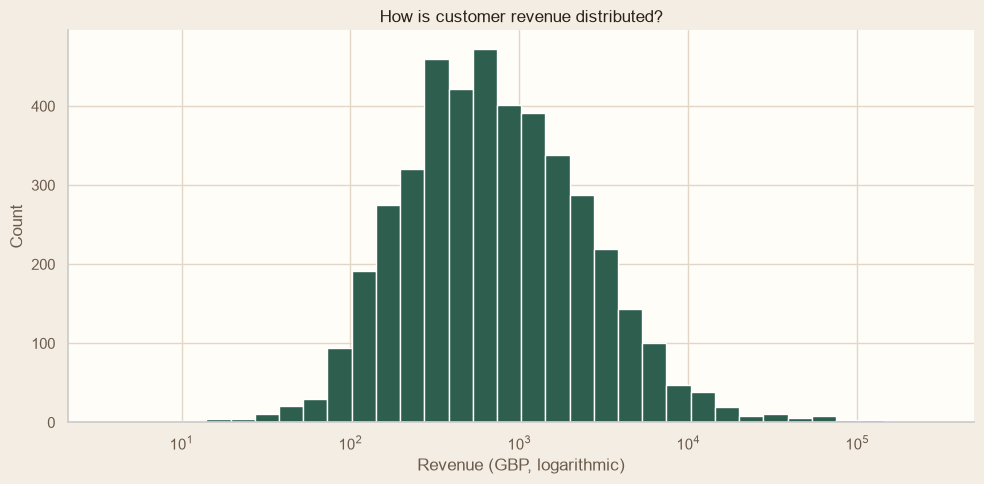

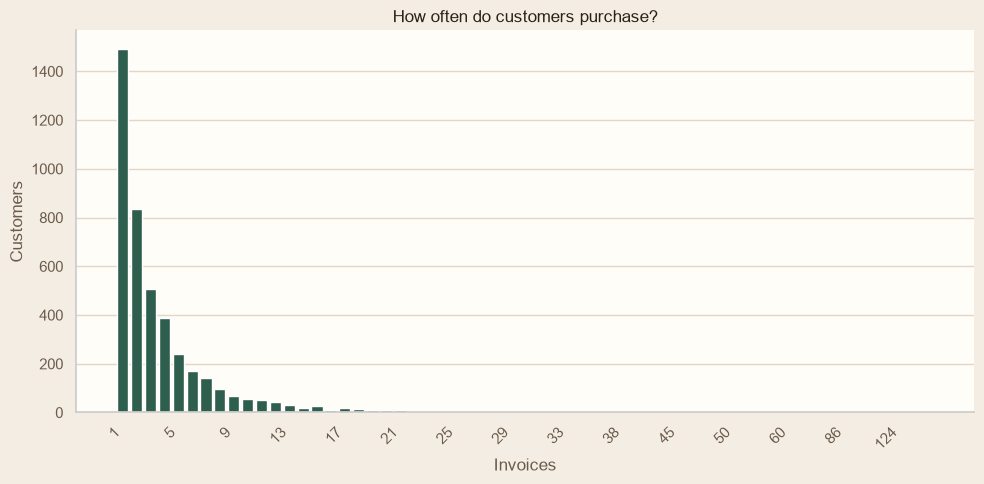

Repeat customer percentage: 65.58321807284463


In [14]:
display(a.customers(sales).head(10))
display(a.customers(sales).sort_values("Frequency",ascending=False).head(10))
display(v.distribution(a.customers(sales).Revenue,"How is customer revenue distributed?")); plt.close("all")
display(v.chart(a.frequency(sales),"Customers","How often do customers purchase?")); plt.close("all")
print("Repeat customer percentage:",k["repeat_customer_pct"])

## 15 Geography

Inspect both the home market and the other markets; customer counts have incomplete ID coverage.

,Revenue,Invoices,Customers,AverageInvoiceRevenue
Country,,,,
United Kingdom,9001744.094,18019,3920,499.569571
Netherlands,285446.340,94,9,3036.663191
EIRE,283140.520,288,3,983.126806
Germany,228678.400,457,94,500.390372
France,209625.370,392,87,534.758597
Australia,138453.810,57,9,2429.014211
Spain,61558.560,90,30,683.984000
Switzerland,57067.600,54,21,1056.807407
Belgium,41196.340,98,25,420.370816


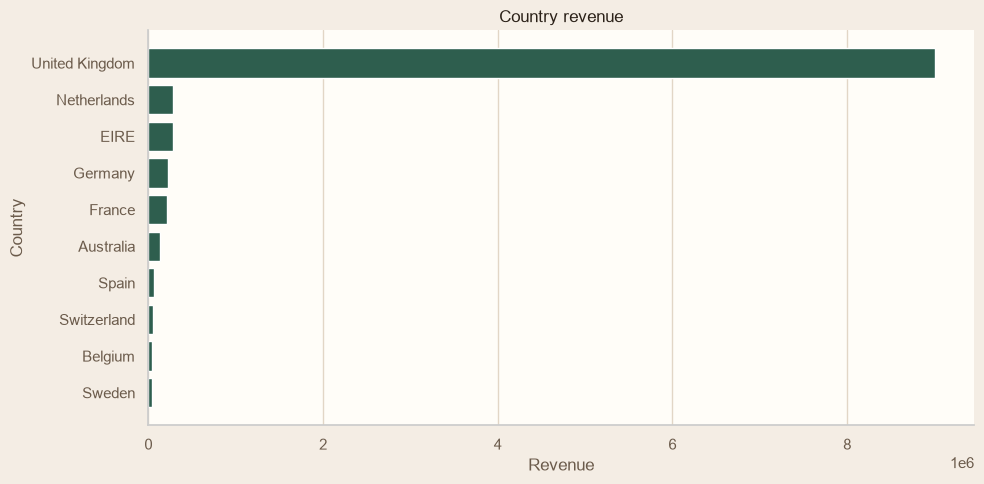

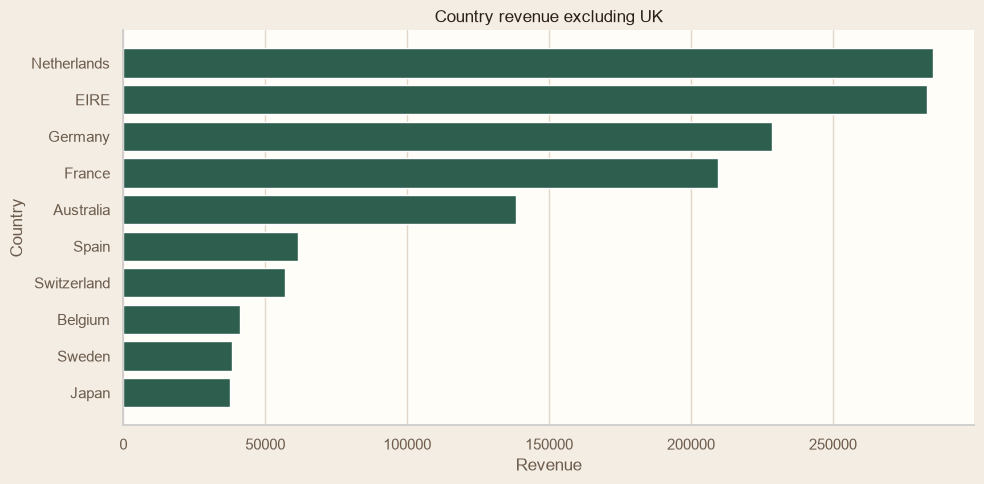

In [15]:
geo=a.countries(sales)
display(geo)
for table,title in [(geo.head(10),"Country revenue"),(geo.drop(index="United Kingdom",errors="ignore").head(10),"Country revenue excluding UK")]:
    display(v.chart(table,"Revenue",title,horizontal=True)); plt.close("all")

## 16 Returns/cancellations

Cancellations cannot reliably be matched to original purchases; value relative to gross sales is not a refund rate.

{'cancellation_invoices': 3836,
 'negative_quantity_records': 10587,
 'cancelled_value_relative_to_gross_pct': 8.400398628287013}

,Lines,Invoices
StockCode,,
22423,180,180
22960,87,87
22720,73,73
21232,60,57
22699,54,54
22197,50,50
22666,47,47
85099B,44,43
20725,44,43


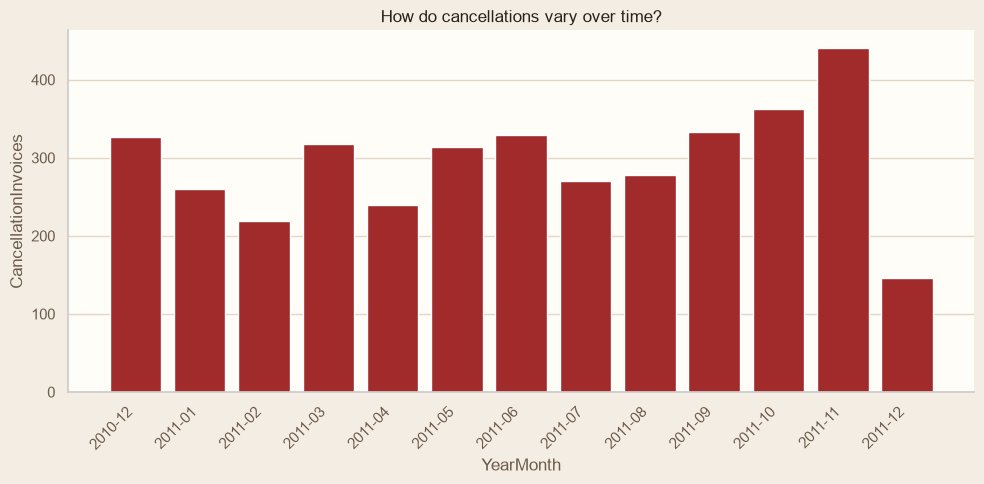

In [16]:
ret=a.returns_analysis(quality,sales)
display({key:value for key,value in ret.items() if key not in ["trend","products"]})
display(ret["products"].head(10))
display(v.chart(ret["trend"],"CancellationInvoices","How do cancellations vary over time?",cancellation=True)); plt.close("all")

## 17 RFM and statistics

Average percentile ranks keep ties together; bins may be empty. Segments are descriptive rules. IQR flags are retained. Mann–Whitney assumes independent observations; temporal dependence, missing trading dates and seasonality limit inference.

,Revenue,Frequency,LastPurchase,Recency,R,F,M,Segment
CustomerID,,,,,,,,
14646,280206.02,73,2011-12-08 12:12:00,2,5,5,5,Champions
18102,259657.30,60,2011-12-09 11:50:00,1,5,5,5,Champions
17450,194390.79,46,2011-12-01 13:29:00,9,5,5,5,Champions
16446,168472.50,2,2011-12-09 09:15:00,1,5,3,5,Loyal
14911,143711.17,201,2011-12-08 15:54:00,2,5,5,5,Champions


,Customers,Revenue,RevenueSharePct
Segment,,,
At Risk,765,919286.912,10.343933
Champions,911,5676143.380,63.868684
Developing,632,265517.471,2.987636
Lost,625,272271.440,3.063633
Loyal,1169,1677789.041,18.878695
New,236,76200.650,0.857419


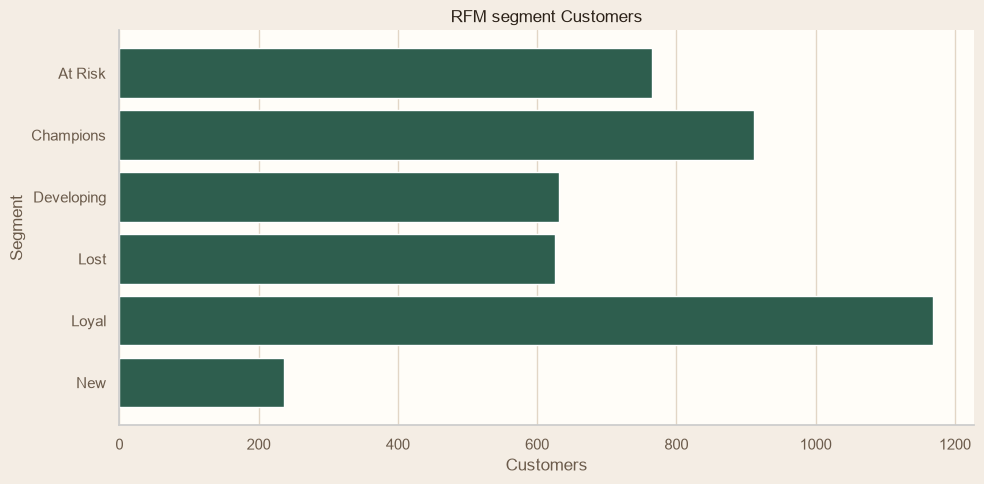

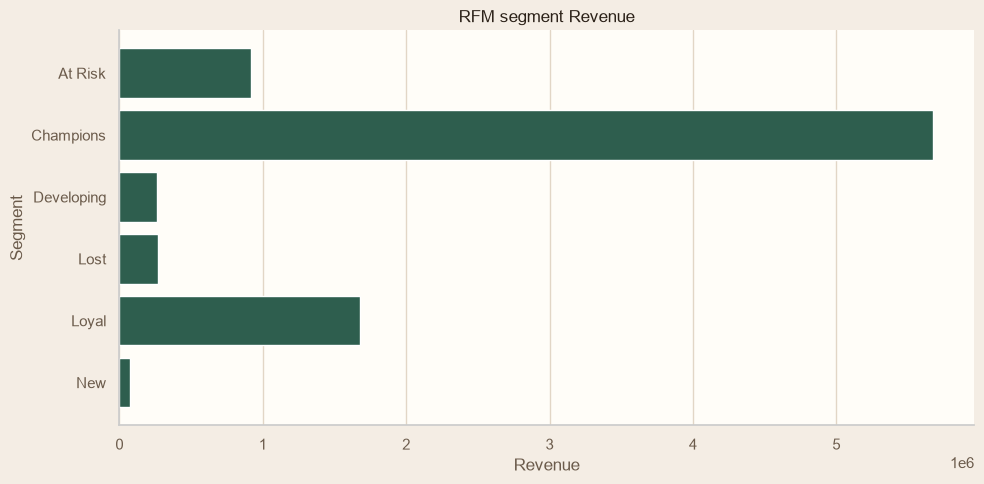

{'Revenue_outliers': 1811,
 'Revenue_outlier_revenue_pct': 47.81953378165559,
 'Units_outliers': 1445,
 'Units_outlier_revenue_pct': 38.87671118256851,
 'units_revenue_spearman': 0.8389840421682713,
 'mann_whitney_p': 4.968124493926503e-17,
 'rank_biserial_weekday_minus_weekend': 0.7502745098039216,
 'weekday_median': 32630.269999999997,
 'weekend_median': 12357.519999999999,
 'weekday_days': 255,
 'weekend_days': 50}

In [17]:
display(a.rfm(sales).head())
display(a.segments(sales))
for value in ["Customers","Revenue"]:
    display(v.chart(a.segments(sales),value,"RFM segment "+value,horizontal=True)); plt.close("all")
display(a.statistics(sales))

## 18 Key findings

The following interpretation is generated from actual executed outputs. Each observation includes its supporting metric.

In [18]:
display(Markdown(findings(sales,quality,report)))

### Sales scale
Observation → Supporting metric: Gross positive-sales revenue is £10,642,110.80 across 19,960 invoices.

Business interpretation: This measures positive sales activity. Suggested action: Use this baseline to monitor sales value. Limitation/uncertainty: No costs or matched refunds; this is not profit or net revenue.

### Product leaders
Observation → Supporting metric: 22423 (REGENCY CAKESTAND 3 TIER) leads merchandise revenue at £174,156.54.

Business interpretation: Sales value is uneven across merchandise. Suggested action: Investigate stock availability for leading products. Limitation/uncertainty: Revenue does not establish margin or future demand.

### Volume versus value
Observation → Supporting metric: 16045 has quantity rank 102 and revenue rank 2387.

Business interpretation: High unit volume can differ from revenue contribution. Suggested action: Investigate pricing and fulfillment workload. Limitation/uncertainty: Unit price and pack conventions can differ.

### Complete-month peak
Observation → Supporting metric: 2011-11 has the highest complete-month revenue (£1,503,866.78); 2011-02 the lowest (£522,545.56).

Business interpretation: Activity varies within the historical window. Suggested action: Test inventory planning around observed peaks. Limitation/uncertainty: Boundary partial months are excluded; this is not a current forecast.

### Geography
Observation → Supporting metric: United Kingdom contributes 84.59% of gross sales.

Business interpretation: The retailer depends heavily on its leading market. Suggested action: Investigate smaller markets separately. Limitation/uncertainty: One UK retailer; missing IDs affect customer counts.

### Repeat purchasing
Observation → Supporting metric: 65.58% of identified customers purchased on multiple distinct invoices; customer 12748 has 209 invoices.

Business interpretation: Repeat activity is observable within this window. Suggested action: Test retention outreach for established customers. Limitation/uncertainty: Purchases outside this window and unidentified customers are invisible.

### Concentration
Observation → Supporting metric: Top 10 products account for 9.09% of gross sales; top 20% of identified customers account for 74.68% of identified revenue.

Business interpretation: Customer dependence deserves monitoring. Suggested action: Investigate service needs of major accounts. Limitation/uncertainty: Product and customer percentages use different denominators.

### Segments
Observation → Supporting metric: Champions is the largest revenue segment (£5,676,143.38).

Business interpretation: RFM describes historical customer behavior. Suggested action: Test differentiated service by segment. Limitation/uncertainty: Heuristic quantile scores are not validated predictions.

### Cancellations
Observation → Supporting metric: 3,836 cancellation invoices; cancelled value relative to gross sales is 8.40%.

Business interpretation: Cancellations warrant operational investigation. Suggested action: Investigate cancellation product patterns and source records. Limitation/uncertainty: Cannot reliably match original sales or infer definitive refund rates.

### Identity coverage
Observation → Supporting metric: 16.49% of sales revenue has no CustomerID.

Business interpretation: Customer analysis covers a subset of sales. Suggested action: Investigate identity capture quality. Limitation/uncertainty: Missing identifiers cannot be imputed reliably.

## 19 Recommendations

Actions are investigations or tests, with uncertainty stated, not promises to increase profit.

In [19]:
display(Markdown("\n\n".join(line for line in findings(sales,quality,report).split("\n\n") if "Suggested action:" in line)))

Business interpretation: This measures positive sales activity. Suggested action: Use this baseline to monitor sales value. Limitation/uncertainty: No costs or matched refunds; this is not profit or net revenue.

Business interpretation: Sales value is uneven across merchandise. Suggested action: Investigate stock availability for leading products. Limitation/uncertainty: Revenue does not establish margin or future demand.

Business interpretation: High unit volume can differ from revenue contribution. Suggested action: Investigate pricing and fulfillment workload. Limitation/uncertainty: Unit price and pack conventions can differ.

Business interpretation: Activity varies within the historical window. Suggested action: Test inventory planning around observed peaks. Limitation/uncertainty: Boundary partial months are excluded; this is not a current forecast.

Business interpretation: The retailer depends heavily on its leading market. Suggested action: Investigate smaller markets separately. Limitation/uncertainty: One UK retailer; missing IDs affect customer counts.

Business interpretation: Repeat activity is observable within this window. Suggested action: Test retention outreach for established customers. Limitation/uncertainty: Purchases outside this window and unidentified customers are invisible.

Business interpretation: Customer dependence deserves monitoring. Suggested action: Investigate service needs of major accounts. Limitation/uncertainty: Product and customer percentages use different denominators.

Business interpretation: RFM describes historical customer behavior. Suggested action: Test differentiated service by segment. Limitation/uncertainty: Heuristic quantile scores are not validated predictions.

Business interpretation: Cancellations warrant operational investigation. Suggested action: Investigate cancellation product patterns and source records. Limitation/uncertainty: Cannot reliably match original sales or infer definitive refund rates.

Business interpretation: Customer analysis covers a subset of sales. Suggested action: Investigate identity capture quality. Limitation/uncertainty: Missing identifiers cannot be imputed reliably.

## 20 Limitations

Historical window, one UK retailer, uncertain within-day completeness, partial boundary months, missing IDs, inconsistent labels, unmatched cancellations and no cost information constrain conclusions.

In [20]:
print("Observed dates:",report["date_min"],"to",report["date_max"])
print("Missing customer revenue share (%):",k["unidentified_revenue_pct"])
print("Non-product codes observed:",report["observed_non_product_codes"])

Observed dates: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Missing customer revenue share (%): 16.490167621073752
Non-product codes observed: ['AMAZONFEE', 'B', 'BANK CHARGES', 'C2', 'D', 'DOT', 'M', 'PADS', 'POST', 'S', 'gift_0001_10', 'gift_0001_20', 'gift_0001_30', 'gift_0001_40', 'gift_0001_50', 'm']


## 21 Conclusion

Sales, customer, product and quality evidence support focused investigation. Consult the shared metric definitions before interpreting any chart.

In [21]:
display(Markdown((ROOT/"docs/metric_definitions.md").read_text()))

# Metric definitions

All monetary values are GBP. The positive-sales view consists of deduplicated non-cancellation lines with valid dates/invoice IDs, Quantity > 0 and UnitPrice > 0. Non-product codes contribute to sales revenue but never merchandise rankings. Identified means CustomerID is present. All metrics use the supplied filtered frame unless stated otherwise.

| Metric | Formula / denominator / rows |
|---|---|
| Gross positive-sales revenue | Sum(Quantity × UnitPrice), positive sales only; never profit or net revenue |
| Units | Sum Quantity, including eligible non-product lines |
| Invoices | Distinct InvoiceNo, never line counts |
| Products | Distinct merchandise StockCode |
| Customers | Distinct non-missing CustomerID |
| Mean / median invoice revenue | Mean / median of distinct invoice line-revenue sums |
| Mean / median customer revenue | Mean / median of identified customer revenue sums; denominator excludes unidentified revenue |
| Unidentified revenue share | Sales revenue on missing-ID lines / all positive sales revenue × 100 |
| Missing-ID row share | Missing-ID positive-sales rows / all positive-sales rows × 100 |
| Repeat-customer rate | Identified customers with >1 distinct sales invoice / identified customers × 100; within selected window and filters |
| Purchase frequency | Distinct invoices per identified customer; distribution counts customers at each frequency |
| Daily revenue | Sum Revenue per observed date; missing dates are absent, not filled with zero |
| Monthly revenue / invoices | Revenue sum / distinct invoice count by calendar month in chronological order; missing months remain NaN |
| Partial month | Observation/filter start later than calendar first day or end earlier than last day; boundary-day completeness itself is unknown |
| MoM | (Current − Previous) / Previous × 100; NaN if previous missing/zero. MoMPartial flags either month incomplete |
| Weekday revenue | Revenue summed by weekday, Monday through Sunday; not normalized for number of days |
| Hour transactions | Distinct invoices per recorded hour |
| Product revenue / quantity | Sum by merchandise StockCode, with one modal description; ties in rankings resolved by code |
| Product revenue share / concentration | Selected product revenue / ALL positive-sales revenue × 100, including non-product denominator |
| Customer concentration | Selected identified-customer revenue / ALL identified-customer revenue × 100; top 20% rounds customer count upward |
| Pareto | Cumulative ranked merchandise revenue / all positive-sales revenue × 100; may finish below 100% due to non-products |
| Country revenue / invoices / customers | Sum revenue / distinct invoices / distinct identified customers by recorded country; mean invoice revenue = country revenue / country invoices |
| Cancellation invoices | Distinct InvoiceNo starting C, after exact deduplication; not necessarily matched returns |
| Negative-quantity records | Deduplicated quality records with Quantity < 0, including cancellation lines |
| Cancelled value relative to gross sales | Sum absolute line value on C invoices / gross positive-sales revenue × 100 in the same dates; NOT refund or return rate |
| Cancellation products | Cancellation line count and distinct invoice count by merchandise StockCode |
| IQR outliers | Invoice revenue or units outside Q1−1.5×IQR to Q3+1.5×IQR; retained. Revenue share uses all invoice revenue |
| Spearman correlation | Rank correlation between invoice total units and invoice revenue; descriptive, not causal |
| Mann–Whitney comparison | Observed weekday versus weekend daily revenues; two-sided U p-value; effect size = 2U/(n_weekday×n_weekend)−1; positive favors weekday. Medians and group day counts reported. Days may be temporally dependent; missing trading days and seasonality confound interpretation |
| RFM Recency | Days since last identified purchase, reference one day after latest sales date in supplied data |
| RFM Frequency / Monetary | Distinct identified invoices / identified revenue in supplied data |
| RFM scores | ceil(average percentile rank × 5), clipped 1–5. Recency ranks reversed. Equal values share score; some bins may be empty, particularly tiny data |
| RFM segments | First matching: Champions R≥4,F≥4,M≥4; At Risk R≤2,F≥3; Lost R=1; Loyal F≥3; New R≥4,F≤2; otherwise Developing |
| Segment contribution | Segment identified revenue / all identified revenue × 100; size counts identified customers |

The full-source cleaning audit is provenance metadata and is not recomputed by dashboard filters. Date-window quality tables are filtered by date only; country/product/price filters apply to sales metrics. Cleaning exclusion reasons are mutually exclusive in this priority: cancellation, invalid date, missing invoice, invalid quantity, nonpositive quantity, invalid price, nonpositive price. A row with several problems is counted once in reconciliation.
